# 01 · Data exploration

Start with one extracted ETL1 file: `ETL1C_07`. Load its metadata and associate each record with its PNG image. Explore the data yourself in the exercises below.

Select the project's `.venv` as the notebook kernel before running the cells.


In [2]:
from pathlib import Path

import pandas as pd

# Support running the notebook from the repository root or notebooks/.
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

# ETL1 is a local directory or a local symbolic link, excluded from Git.
ETL1_DIR = PROJECT_ROOT / "ETL1"
SOURCE_FILE = "ETL1C_07"
EXTRACTED_DIR = ETL1_DIR / f"{SOURCE_FILE}_unpack"
METADATA_PATH = EXTRACTED_DIR / "meta.csv"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Metadata not found: {METADATA_PATH}\n"
        "Extract ETL1 locally as described in data/README.md, "
        "or update ETL1_DIR to point to your extracted data."
    )


## Load the metadata

The first CSV column contains the record index, not a character class. Read it as the index, then expose it as `record_index`. Keep character codes as text.


In [3]:
metadata = pd.read_csv(
    METADATA_PATH,
    index_col=0,
    keep_default_na=False,
    dtype={"char": "string", "unicode": "string"},
)
metadata = metadata.rename_axis("record_index").reset_index()

# The extraction utility names PNGs with five-digit record indices.
metadata["image_path"] = metadata["record_index"].map(
    lambda record_index: EXTRACTED_DIR / f"{record_index:05d}.png"
)

metadata.head()


,record_index,char,unicode,image_path
0,0,ア,0x30a2,/Users/nailito/Desktop/Data/katakana-recogniti...
1,1,ア,0x30a2,/Users/nailito/Desktop/Data/katakana-recogniti...
2,2,ア,0x30a2,/Users/nailito/Desktop/Data/katakana-recogniti...
3,3,ア,0x30a2,/Users/nailito/Desktop/Data/katakana-recogniti...
4,4,ア,0x30a2,/Users/nailito/Desktop/Data/katakana-recogniti...


## Check the image references

The table contains paths, not decoded pixel arrays. Images can be opened individually when needed, without loading the entire dataset into memory.


In [4]:
missing_images = metadata.loc[
    ~metadata["image_path"].map(Path.is_file),
    "image_path",
]

if not missing_images.empty:
    raise FileNotFoundError(
        f"{len(missing_images)} referenced PNG files are missing. "
        f"First missing file: {missing_images.iloc[0]}"
    )

print(f"Loaded {len(metadata):,} records from {SOURCE_FILE}.")
print("All referenced PNG files exist.")


Loaded 11,288 records from ETL1C_07.
All referenced PNG files exist.


Let’s look at the number of examples per character in ETL1C_07

In [5]:
metadata.groupby("char").count()["record_index"]

char
ア    1411
イ    1411
ウ    1411
エ    1411
オ    1411
カ    1411
キ    1411
ク    1411
Name: record_index, dtype: int64

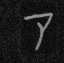

(64, 63)
L


In [6]:
from PIL import Image

image = Image.open(metadata.iloc[0]["image_path"])
display(image)
print(image.size) 
print(image.mode) 

These are 64x63 images, in greyscale (L)

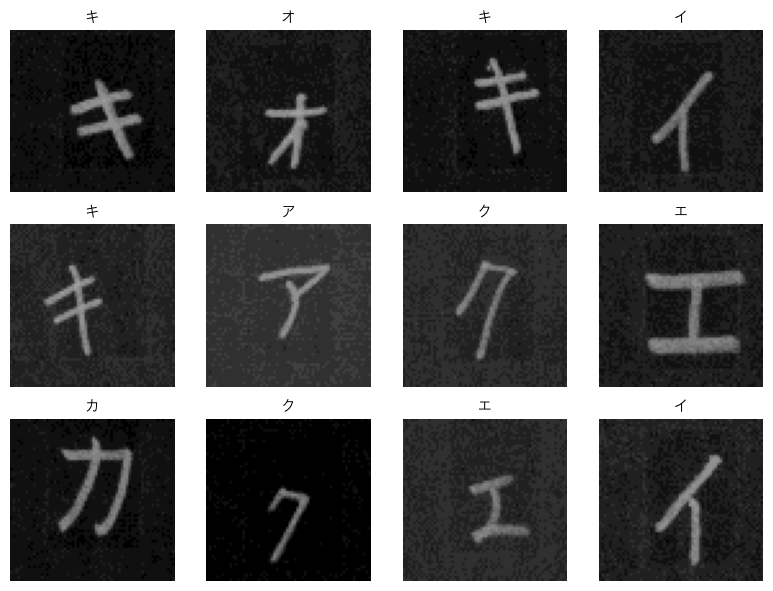

In [7]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from PIL import Image

jp_font = FontProperties(
    fname="/System/Library/Fonts/Hiragino Sans GB.ttc"
)

samples = metadata.sample(n=12, random_state=23)

fig, axes = plt.subplots(3, 4, figsize=(8, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(row["image_path"]) as image:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(row["char"], fontproperties=jp_font)
    ax.set_axis_off()

plt.tight_layout()
plt.show()